In [28]:
import glob
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

files = glob.glob('/kaggle/input/**/healthcare-dataset-stroke-data.csv', recursive=True)
df = pd.read_csv(files[0])
print("Rows, Columns:", df.shape)
print(df.columns.tolist())
df.head()

Rows, Columns: (5110, 12)
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 1. Dataset Description
- Title: Stroke Prediction Dataset
- Source: Kaggle (fedesoriano) - link yahan paste karo
- Size: 5110 rows, 12 columns
- Main features: age, gender, hypertension, heart_disease, ever_married, work_type,
  Residence_type, avg_glucose_level, bmi, smoking_status
- Target: stroke (1 = stroke aaya, 0 = nahi aaya)
- Objective: Patient ki health aur lifestyle information se stroke ka risk predict karna.

bmi    201
dtype: int64
BMI missing: 3.93%
bmi
bmi present    0.042575
bmi missing    0.199005
Name: stroke, dtype: float64


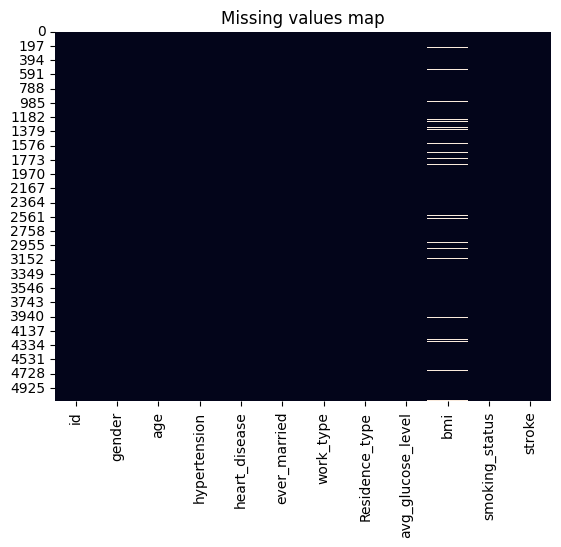

In [29]:
missing = df.isnull().sum()
print(missing[missing > 0])
print(f"BMI missing: {df['bmi'].isnull().mean()*100:.2f}%")

# Kya missing hona khud koi information deta hai?
print(df.groupby(df['bmi'].isnull())['stroke'].mean().rename({False:'bmi present', True:'bmi missing'}))

sns.heatmap(df.isnull(), cbar=False); plt.title("Missing values map"); plt.show()

Problem: bmi mein 201 values missing hain (~3.9%).
Method: Median imputation, lekin split ke baad (Section 3 mein).
Why: BMI right-skewed hai aur outliers hain, to mean bigar jata hai, median safe hai. Imputation split se pehle karte to test data ki information train mein aa jati (data leakage). Saath mein bmi_missing flag bhi banayenge.

In [30]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate ids:", df['id'].duplicated().sum())
print("Duplicates (id ke baghair):", df.drop(columns='id').duplicated().sum())

df = df.drop_duplicates()
df = df.drop(columns='id')

Duplicate rows: 0
Duplicate ids: 0
Duplicates (id ke baghair): 0


In [31]:
for c in df.select_dtypes('object').columns:
    print(c, "->", df[c].unique())

# Column names aur text ko consistent banao
df.columns = df.columns.str.lower()          # Residence_type -> residence_type
for c in df.select_dtypes('object').columns:
    df[c] = df[c].str.strip().str.lower()

print(df['gender'].value_counts())

gender -> ['Male' 'Female' 'Other']
ever_married -> ['Yes' 'No']
work_type -> ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type -> ['Urban' 'Rural']
smoking_status -> ['formerly smoked' 'never smoked' 'smokes' 'Unknown']
gender
female    2994
male      2115
other        1
Name: count, dtype: int64


In [32]:
# 'other' gender sirf 1 row hai, model us se kuch seekh nahi sakta
df = df[df['gender'] != 'other']

# Logical consistency check: bachchon ki shaadi?
print("Age<18 aur married:", ((df['age'] < 18) & (df['ever_married'] == 'yes')).sum())
print(df[df['work_type'] == 'children']['age'].describe())

Age<18 aur married: 0
count    687.000000
mean       6.841339
std        4.533364
min        0.080000
25%        2.000000
50%        6.000000
75%       11.000000
max       16.000000
Name: age, dtype: float64


In [33]:
print(df.dtypes)
for c in ['hypertension','heart_disease','stroke']:
    print(c, df[c].unique())
print("Age < 1 saal:", (df['age'] < 1).sum())
print(df['age'].describe())

# Text columns ko category type do
for c in ['work_type', 'smoking_status']:
    df[c] = df[c].astype('category')

gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object
hypertension [0 1]
heart_disease [1 0]
stroke [1 0]
Age < 1 saal: 43
count    5109.000000
mean       43.229986
std        22.613575
min         0.080000
25%        25.000000
50%        45.000000
75%        61.000000
max        82.000000
Name: age, dtype: float64


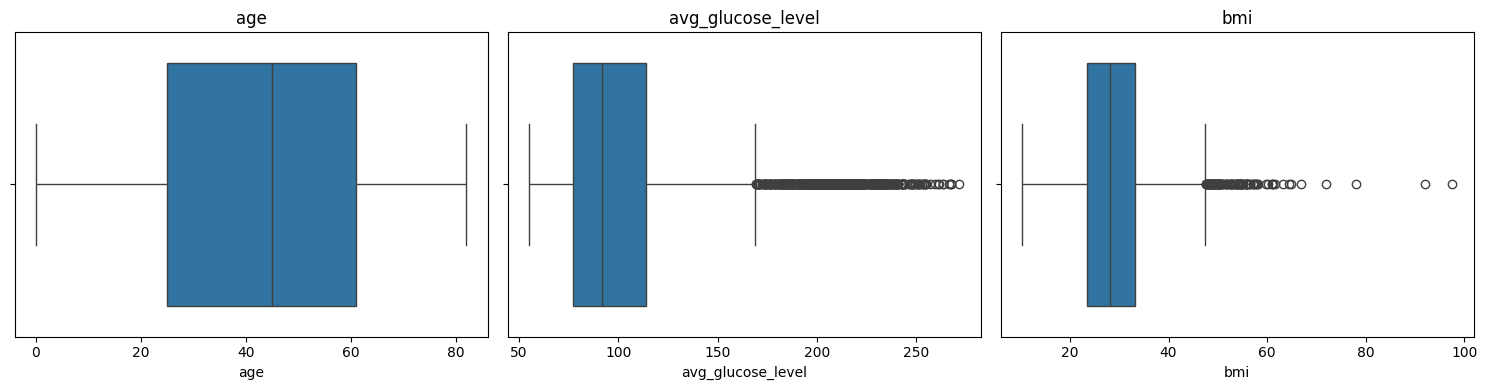

age: IQR bounds = (-29.0, 115.0), outliers = 0
avg_glucose_level: IQR bounds = (22.0, 169.4), outliers = 627
bmi: IQR bounds = (9.1, 47.5), outliers = 110


In [34]:
num_cols = ['age', 'avg_glucose_level', 'bmi']

fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=df[c], ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    print(f"{c}: IQR bounds = ({lo:.1f}, {hi:.1f}), outliers = {n}")

In [35]:
target = 'stroke'
print("Target:", target)
print("Features:", [c for c in df.columns if c != target])

Target: stroke
Features: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']


In [36]:
var_types = pd.DataFrame({
    'Type': ['Numerical (continuous)', 'Binary', 'Nominal categorical', 'Ordinal (engineered)', 'Date/Time'],
    'Columns': ['age, avg_glucose_level, bmi',
                'gender, ever_married, residence_type, hypertension, heart_disease',
                'work_type, smoking_status',
                'age_group, glucose_level (neeche banayenge)',
                'Koi nahi (dataset mein date/time column nahi hai)']
})
display(var_types)

,Type,Columns
0,Numerical (continuous),"age, avg_glucose_level, bmi"
1,Binary,"gender, ever_married, residence_type, hyperten..."
2,Nominal categorical,"work_type, smoking_status"
3,Ordinal (engineered),"age_group, glucose_level (neeche banayenge)"
4,Date/Time,Koi nahi (dataset mein date/time column nahi hai)


In [37]:
df['gender'] = df['gender'].map({'male': 1, 'female': 0})
df['ever_married'] = df['ever_married'].map({'yes': 1, 'no': 0})
df['residence_type'] = df['residence_type'].map({'urban': 1, 'rural': 0})
print(df[['gender','ever_married','residence_type']].isnull().sum())

gender            0
ever_married      0
residence_type    0
dtype: int64


In [38]:
# 1. BMI missing tha ya nahi (imputation se pehle record karo)
df['bmi_missing'] = df['bmi'].isnull().astype(int)

# 2. Age group (ordinal: 0 = bacha ... 4 = buzurg)
df['age_group'] = pd.cut(df['age'], bins=[0, 18, 40, 60, 75, 121], right=False, labels=False)

# 3. Glucose level (medical thresholds: 0 = normal, 1 = pre-diabetic, 2 = diabetic range)
df['glucose_level'] = pd.cut(df['avg_glucose_level'], bins=[0, 100, 126, 500], right=False, labels=False)

# 4. Total risk factors
df['risk_factors'] = df['hypertension'] + df['heart_disease']

print(df[['bmi_missing','age_group','glucose_level','risk_factors']].describe().T)
print(df.groupby('age_group')['stroke'].mean().round(3))
print(df.groupby('glucose_level')['stroke'].mean().round(3))

                count      mean       std  min  25%  50%  75%  max
bmi_missing    5109.0  0.039342  0.194427  0.0  0.0  0.0  0.0  1.0
age_group      5109.0  1.778626  1.204974  0.0  1.0  2.0  3.0  4.0
glucose_level  5109.0  0.578978  0.792163  0.0  0.0  0.0  1.0  2.0
risk_factors   5109.0  0.151497  0.391956  0.0  0.0  0.0  0.0  2.0
age_group
0    0.002
1    0.005
2    0.038
3    0.092
4    0.197
Name: stroke, dtype: float64
glucose_level
0    0.036
1    0.037
2    0.102
Name: stroke, dtype: float64


In [39]:
X = df.drop(columns=target)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Stroke % train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

Train: (4087, 14) | Test: (1022, 14)
Stroke % train: 0.049 | test: 0.049


In [40]:
for c in ['avg_glucose_level', 'bmi']:
    q1, q3 = X_train[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    X_train[c] = X_train[c].clip(lo, hi)
    X_test[c]  = X_test[c].clip(lo, hi)     # test par bhi TRAIN ke bounds
    print(f"{c}: bounds = ({lo:.1f}, {hi:.1f})")

avg_glucose_level: bounds = (22.6, 168.9)
bmi: bounds = (9.1, 47.5)


Skewness:
 age                 -0.14
avg_glucose_level    0.93
bmi                  0.48
dtype: float64


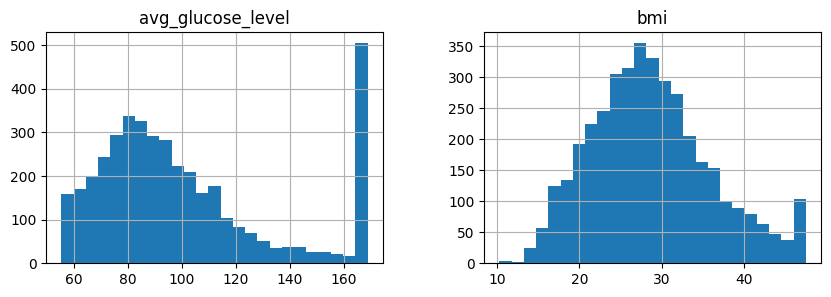

In [41]:
skew_before = X_train[['age','avg_glucose_level','bmi']].skew().round(2)
print("Skewness:\n", skew_before)

X_train[['avg_glucose_level','bmi']].hist(figsize=(10,3), bins=25); plt.show()

In [42]:
skewed_cols  = ['avg_glucose_level', 'bmi']
scale_cols   = ['age', 'risk_factors', 'age_group', 'glucose_level']
binary_cols  = ['gender', 'hypertension', 'heart_disease', 'ever_married',
                'residence_type', 'bmi_missing']
nominal_cols = ['work_type', 'smoking_status']

skew_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),                       # missing BMI
    ('log',    FunctionTransformer(np.log1p, feature_names_out='one-to-one')),  # skew kam
    ('scale',  StandardScaler()),                                       # mean 0, std 1
])

preprocessor = ColumnTransformer([
    ('skew',  skew_pipe, skewed_cols),
    ('scale', StandardScaler(), scale_cols),
    ('bin',   'passthrough', binary_cols),
    ('nom',   OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal_cols),
])

# fit SIRF train par, transform dono par
X_train_p = preprocessor.fit_transform(X_train)
X_test_p  = preprocessor.transform(X_test)

cols = [c.split('__')[-1] for c in preprocessor.get_feature_names_out()]
X_train_p = pd.DataFrame(X_train_p, columns=cols, index=X_train.index)
X_test_p  = pd.DataFrame(X_test_p,  columns=cols, index=X_test.index)

print("Processed shape:", X_train_p.shape, X_test_p.shape)
print("Missing bachi:", X_train_p.isnull().sum().sum(), X_test_p.isnull().sum().sum())
display(X_train_p.head())

Processed shape: (4087, 21) (1022, 21)
Missing bachi: 0 0


,avg_glucose_level,bmi,age,risk_factors,age_group,glucose_level,gender,hypertension,heart_disease,ever_married,...,bmi_missing,work_type_children,work_type_govt_job,work_type_never_worked,work_type_private,work_type_self-employed,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,smoking_status_unknown
845,-1.076969,0.686488,0.209397,-0.387844,0.183977,-0.733761,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3745,-0.436261,-1.072556,-0.629845,-0.387844,-0.646867,-0.733761,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4184,0.709815,-0.770152,-0.364822,-0.387844,-0.646867,0.533193,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3410,0.400872,0.638129,-0.232310,-0.387844,-0.646867,0.533193,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
284,-0.508999,0.502122,-1.292405,-0.387844,-1.477711,-0.733761,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [43]:
print("Train mean (scaled cols):\n", X_train_p[['age','avg_glucose_level','bmi']].mean().round(3))
print("Train std:\n", X_train_p[['age','avg_glucose_level','bmi']].std().round(3))
print("Test mean:\n", X_test_p[['age','avg_glucose_level','bmi']].mean().round(3))

# Skewness ab
tmp = X_train[['avg_glucose_level','bmi']].apply(np.log1p)
print("Skewness log ke baad:\n", tmp.skew().round(2))

Train mean (scaled cols):
 age                 -0.0
avg_glucose_level   -0.0
bmi                 -0.0
dtype: float64
Train std:
 age                  1.0
avg_glucose_level    1.0
bmi                  1.0
dtype: float64
Test mean:
 age                 -0.006
avg_glucose_level   -0.004
bmi                  0.014
dtype: float64
Skewness log ke baad:
 avg_glucose_level    0.45
bmi                 -0.16
dtype: float64


In [45]:
df.to_csv('/kaggle/working/stroke_cleaned.csv', index=False)
X_train_p.assign(stroke=y_train.values).to_csv('/kaggle/working/stroke_train_processed.csv', index=False)
X_test_p.assign(stroke=y_test.values).to_csv('/kaggle/working/stroke_test_processed.csv', index=False)
print("Saved!")

Saved!


Problem: BMI mein 201 missing values (3.9%) hain.
Method: Median imputation, train data se seekha, split ke baad.
Why: BMI skewed hai to median mean se behtar hai, aur split ke baad karne se leakage nahi hoti.
Result: Missing values 0 ho gayi.

## EDA-1. Dataset Introduction
- **Title:** Stroke Prediction Dataset
- **Source:** Kaggle (fedesoriano) - https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset
- **Rows x Columns:** 5110 x 12 (cleaning ke baad 5109 rows, kyunke 1 'other' gender wali row hata di aur `id` drop ki)
- **Main features:** age, gender, hypertension, heart_disease, ever_married, work_type, residence_type, avg_glucose_level, bmi, smoking_status
- **Target:** `stroke` (1 = stroke aaya, 0 = nahi aaya)
- **Question:** Kaun se health aur lifestyle factors stroke ke risk se sab se zyada juray hue hain?

In [46]:
eda = df.copy()
eda['gender']         = eda['gender'].map({1: 'Male', 0: 'Female'})
eda['ever_married']   = eda['ever_married'].map({1: 'Yes', 0: 'No'})
eda['residence_type'] = eda['residence_type'].map({1: 'Urban', 0: 'Rural'})
eda['hypertension']   = eda['hypertension'].map({1: 'Yes', 0: 'No'})
eda['heart_disease']  = eda['heart_disease'].map({1: 'Yes', 0: 'No'})
eda['work_type']      = eda['work_type'].astype(str)
eda['smoking_status'] = eda['smoking_status'].astype(str)
eda['age_group_lbl']  = eda['age_group'].map({0: '<18', 1: '18-39', 2: '40-59', 3: '60-74', 4: '75+'})
eda['glucose_lbl']    = eda['glucose_level'].map({0: 'Normal', 1: 'Pre-diabetic', 2: 'Diabetic'})

sns.set_style('whitegrid')
print("Shape:", eda.shape)
print("Numerical:", ['age', 'avg_glucose_level', 'bmi'])
print("Categorical:", ['gender','hypertension','heart_disease','ever_married','work_type','residence_type','smoking_status'])
print("Target:", 'stroke')
display(eda.describe().T.round(2))

Shape: (5109, 17)
Numerical: ['age', 'avg_glucose_level', 'bmi']
Categorical: ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'residence_type', 'smoking_status']
Target: stroke


,count,mean,std,min,25%,50%,75%,max
age,5109.0,43.23,22.61,0.08,25.00,45.00,61.00,82.00
avg_glucose_level,5109.0,106.14,45.29,55.12,77.24,91.88,114.09,271.74
bmi,4908.0,28.89,7.85,10.30,23.50,28.10,33.10,97.60
stroke,5109.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00
bmi_missing,5109.0,0.04,0.19,0.00,0.00,0.00,0.00,1.00
age_group,5109.0,1.78,1.20,0.00,1.00,2.00,3.00,4.00
glucose_level,5109.0,0.58,0.79,0.00,0.00,0.00,1.00,2.00
risk_factors,5109.0,0.15,0.39,0.00,0.00,0.00,0.00,2.00


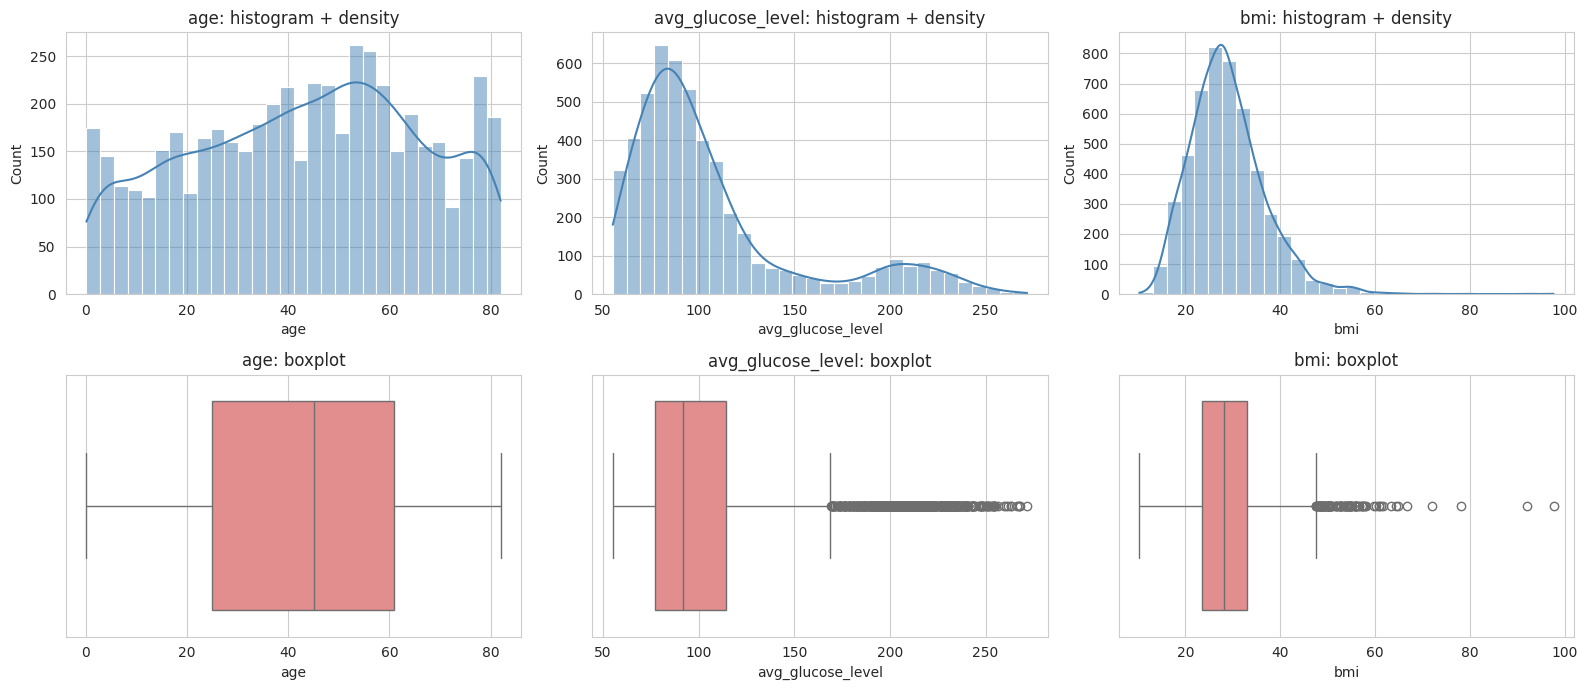

,age,avg_glucose_level,bmi
mean,43.23,106.14,28.89
median,45.00,91.88,28.10
std,22.61,45.29,7.85
skew,-0.14,1.57,1.06


In [47]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for i, c in enumerate(num_cols):
    sns.histplot(eda[c], kde=True, bins=30, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'{c}: histogram + density')
    sns.boxplot(x=eda[c], ax=axes[1, i], color='lightcoral')
    axes[1, i].set_title(f'{c}: boxplot')
plt.tight_layout(); plt.show()

display(eda[num_cols].agg(['mean', 'median', 'std', 'skew']).round(2))

**Interpretation:**
- **age:** 0 se 82 tak poori range mein phaili hui hai aur lagbhag symmetric hai (skew ~0). Boxplot mein koi outlier nahi. Median ~45 saal hai.
- **avg_glucose_level:** right-skewed hai aur do peak nazar aate hain: ek normal range ke paas, doosra ~200 ke qareeb (diabetic range). Boxplot mein ~627 high-value outliers hain.
- **bmi:** thora right-skewed hai, median ~28 (overweight range). Boxplot mein ~110 high outliers hain.
- Outliers ko hum ne remove nahi kiya, kyunke ye asli mareez ho sakte hain. Inhein train ke IQR bounds par clip kiya gaya.

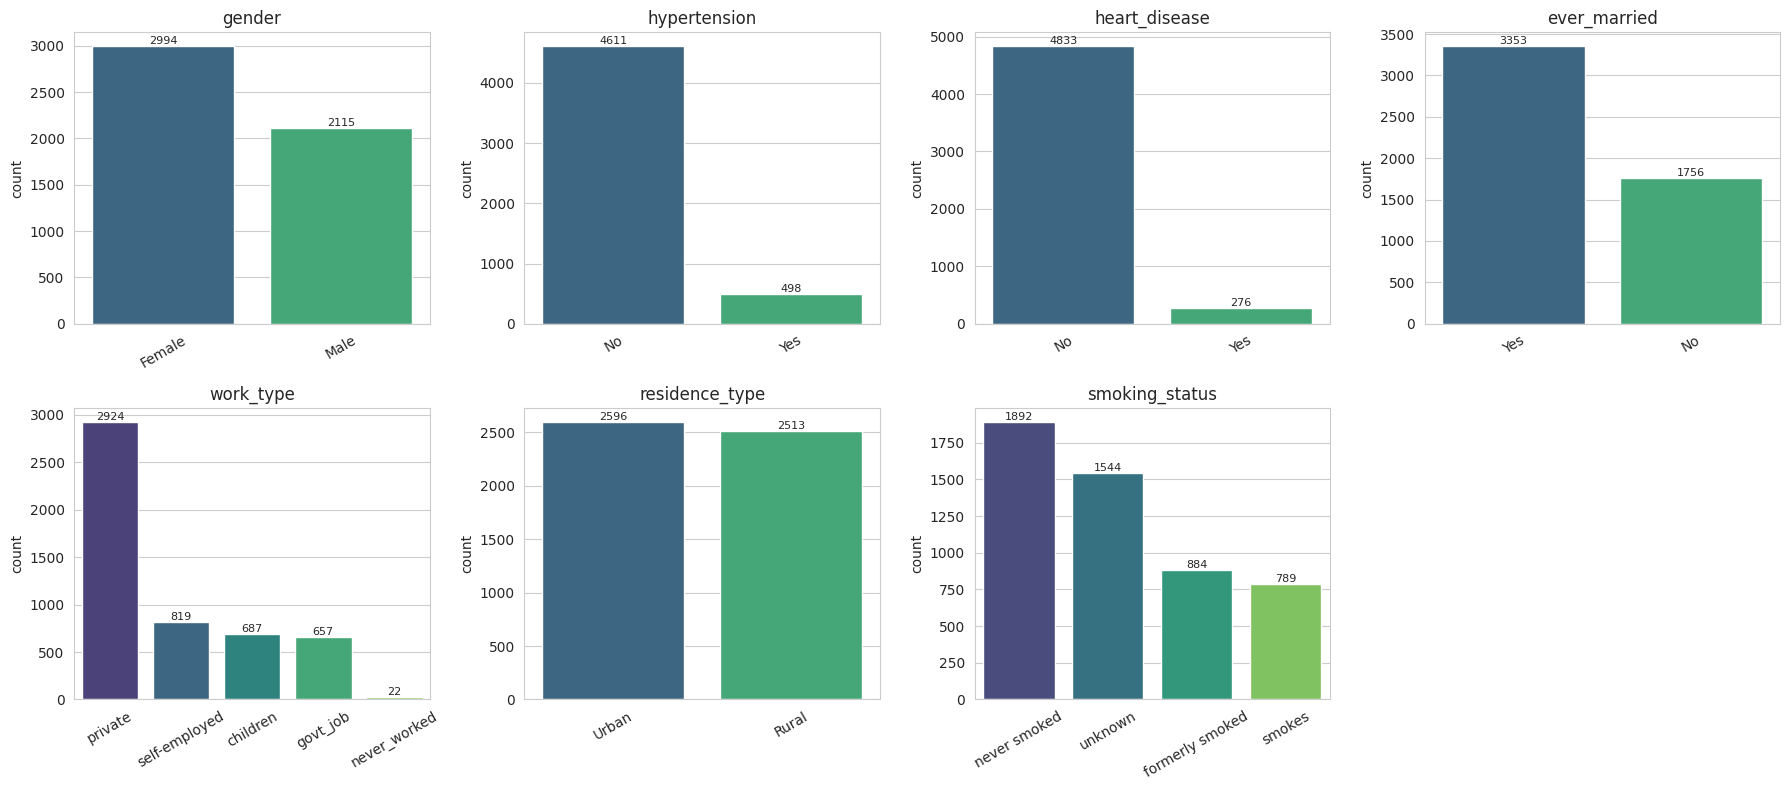

work_type
private          57.2
self-employed    16.0
children         13.4
govt_job         12.9
never_worked      0.4
Name: proportion, dtype: float64 

smoking_status
never smoked       37.0
unknown            30.2
formerly smoked    17.3
smokes             15.4
Name: proportion, dtype: float64 



In [48]:
cat_cols = ['gender', 'hypertension', 'heart_disease', 'ever_married',
            'work_type', 'residence_type', 'smoking_status']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, c in zip(axes, cat_cols):
    order = eda[c].value_counts().index
    sns.countplot(x=eda[c], order=order, ax=ax, palette='viridis')
    ax.set_title(c); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=8)
axes[-1].axis('off')
plt.tight_layout(); plt.show()

for c in ['work_type', 'smoking_status']:
    print((eda[c].value_counts(normalize=True) * 100).round(1), '\n')

**Interpretation:**
- **gender:** Female zyada hain (~59%).
- **hypertension aur heart_disease:** dono mein "No" ka bohot bara hissa hai, yani positive cases kam hain.
- **work_type:** `Private` sab se bara group hai, `Never_worked` bohot chhota.
- **smoking_status:** ~30% records `unknown` hain, ye ek data quality issue hai.
- **residence_type:** Urban aur Rural lagbhag barabar hain.

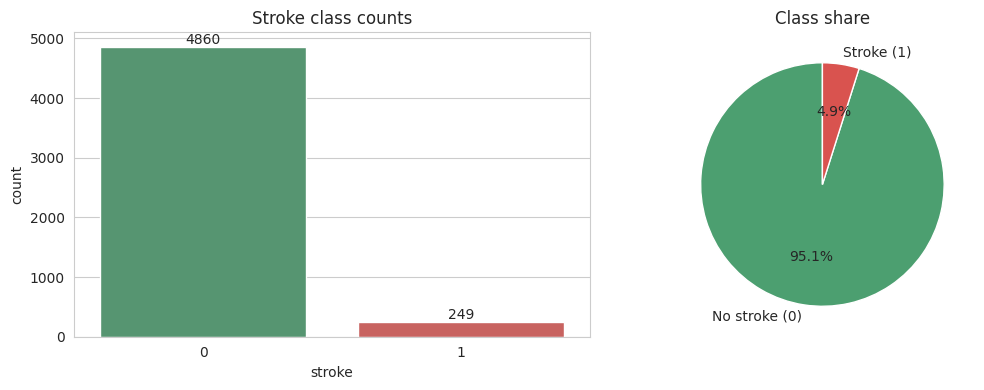

stroke
0    4860
1     249
stroke
0    95.13
1     4.87
Imbalance ratio (0:1) = 19.5 : 1


In [49]:
counts = eda['stroke'].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='stroke', data=eda, ax=axes[0], palette=['#4c9f70', '#d9534f'])
axes[0].set_title('Stroke class counts')
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')
axes[1].pie(counts, labels=['No stroke (0)', 'Stroke (1)'], autopct='%1.1f%%',
            colors=['#4c9f70', '#d9534f'], startangle=90)
axes[1].set_title('Class share')
plt.tight_layout(); plt.show()

print(counts.to_string()); print(pct.to_string())
print(f"Imbalance ratio (0:1) = {counts[0] / counts[1]:.1f} : 1")

**Interpretation:** Target **bohot imbalanced** hai. Sirf ~4.9% patients ko stroke aaya aur ~95% ko nahi (ratio lagbhag 19:1).
Is ka matlab sirf accuracy gumrah kar sakti hai, kyunke sab ko "no stroke" keh dene se bhi ~95% accuracy mil jati hai. Modeling mein stratified split (jo hum ne use ki), class weights ya SMOTE, aur Recall, Precision, F1, ROC-AUC use karne chahiye.

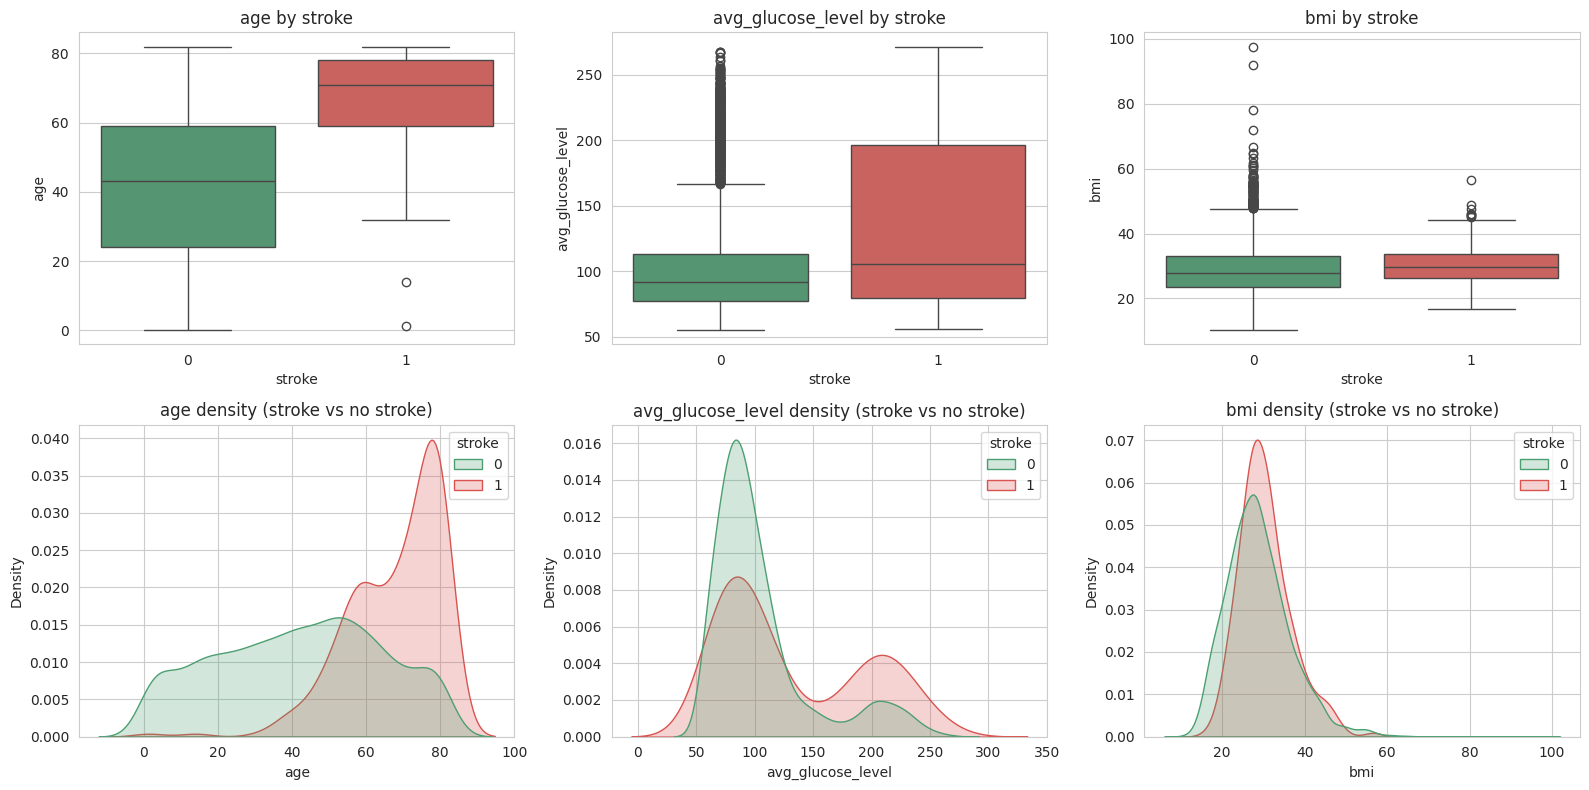

age        avg_glucose_level            bmi       
         mean median              mean  median   mean median
stroke                                                      
0       41.97   43.0            104.79   91.46  28.82   28.0
1       67.73   71.0            132.54  105.22  30.47   29.7

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, c in enumerate(num_cols):
    sns.boxplot(x='stroke', y=c, data=eda, ax=axes[0, i], palette=['#4c9f70', '#d9534f'])
    axes[0, i].set_title(f'{c} by stroke')
    sns.kdeplot(data=eda, x=c, hue='stroke', common_norm=False, fill=True,
                palette=['#4c9f70', '#d9534f'], ax=axes[1, i])
    axes[1, i].set_title(f'{c} density (stroke vs no stroke)')
plt.tight_layout(); plt.show()

display(eda.groupby('stroke')[num_cols].agg(['mean', 'median']).round(2))

**Interpretation:** Stroke wale patients ki age bohot zyada hai (median ~70 vs ~43) aur unka glucose bhi zyada hai. BMI mein farq bohot chhota hai. Yani **age sab se strong separator** hai aur BMI kamzor.

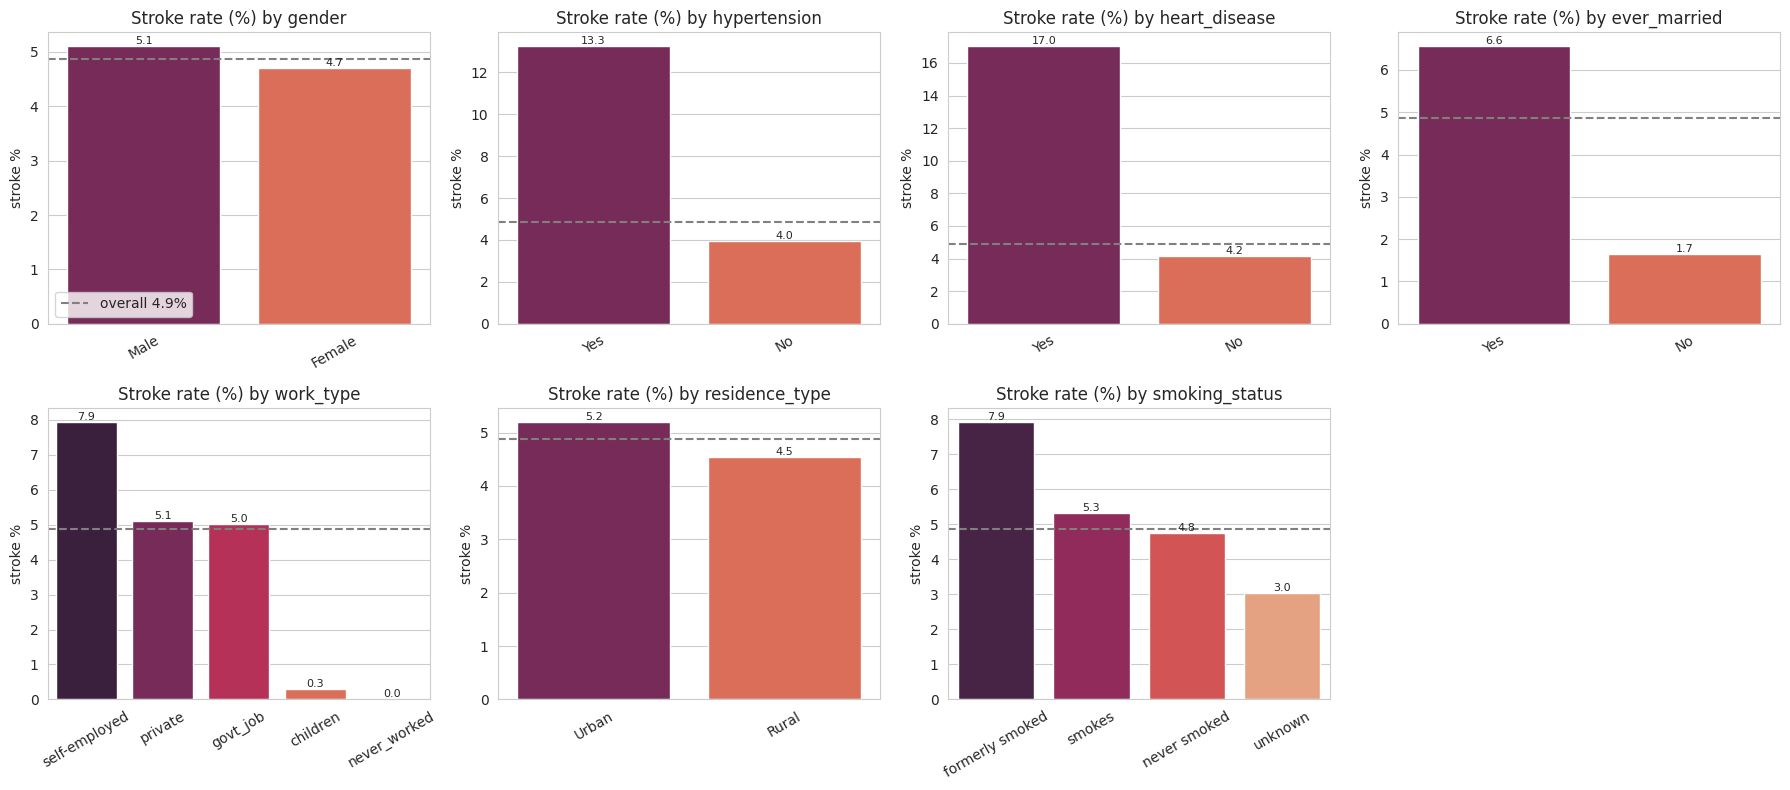

In [51]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, c in zip(axes, cat_cols):
    rate = eda.groupby(c)['stroke'].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette='rocket')
    ax.axhline(eda['stroke'].mean() * 100, color='gray', ls='--', label='overall 4.9%')
    ax.set_title(f'Stroke rate (%) by {c}'); ax.set_xlabel(''); ax.set_ylabel('stroke %')
    ax.tick_params(axis='x', rotation=30)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=8)
axes[0].legend()
axes[-1].axis('off')
plt.tight_layout(); plt.show()

**Interpretation:** `hypertension=Yes` aur `heart_disease=Yes` walon mein stroke rate overall (4.9%) se kai guna zyada hai. `ever_married=Yes` mein bhi rate zyada hai, lekin ye shayad age ka asar hai (shaadi shuda log zyada umar ke hain). `gender` aur `residence_type` mein farq bohot kam hai. `work_type=children` mein rate bohot kam hai.

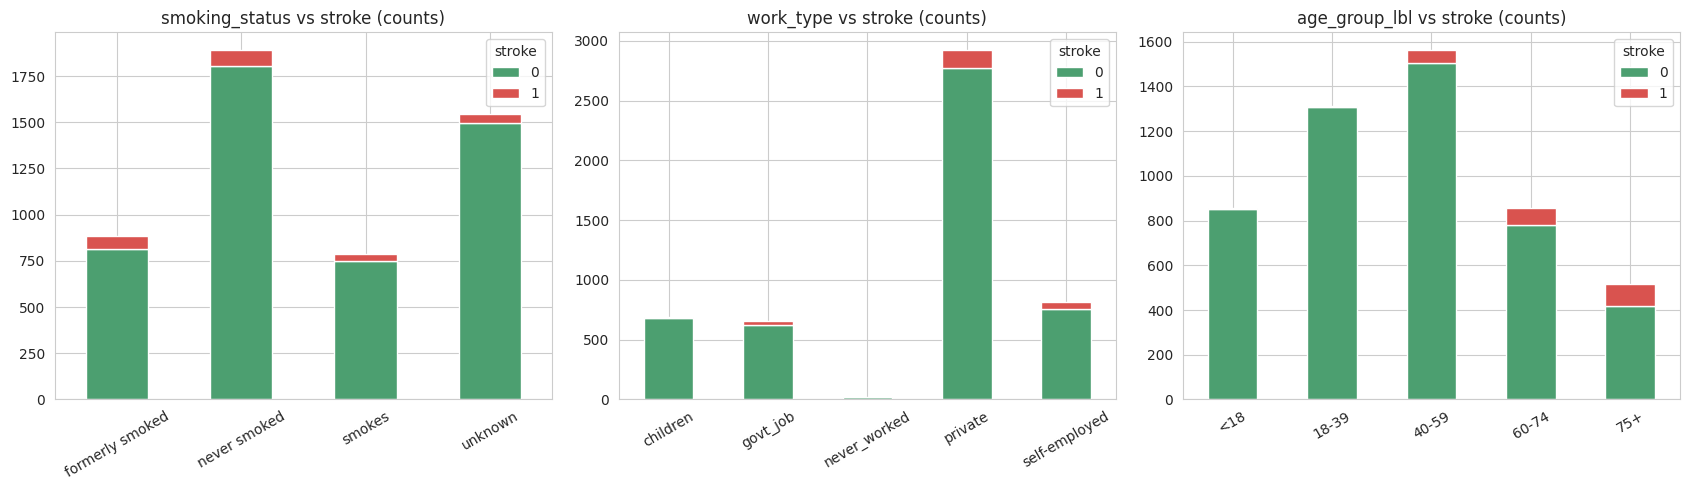

stroke,0,1
smoking_status,,
formerly smoked,92.08,7.92
never smoked,95.24,4.76
smokes,94.68,5.32
unknown,96.96,3.04


In [52]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, c in zip(axes, ['smoking_status', 'work_type', 'age_group_lbl']):
    order = ['<18', '18-39', '40-59', '60-74', '75+'] if c == 'age_group_lbl' else None
    ct = pd.crosstab(eda[c], eda['stroke'])
    if order: ct = ct.loc[order]
    ct.plot(kind='bar', stacked=True, ax=ax, color=['#4c9f70', '#d9534f'])
    ax.set_title(f'{c} vs stroke (counts)'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

display((pd.crosstab(eda['smoking_status'], eda['stroke'], normalize='index') * 100).round(2))

**Interpretation:** `formerly smoked` aur `smokes` walon mein stroke % `never smoked` se thora zyada hai, lekin farq bara nahi. `unknown` category mein bohot se bachay shamil hain, is liye us ka rate kam hai. Age group mein 60+ ke baad stroke ka hissa tez barhta hai.

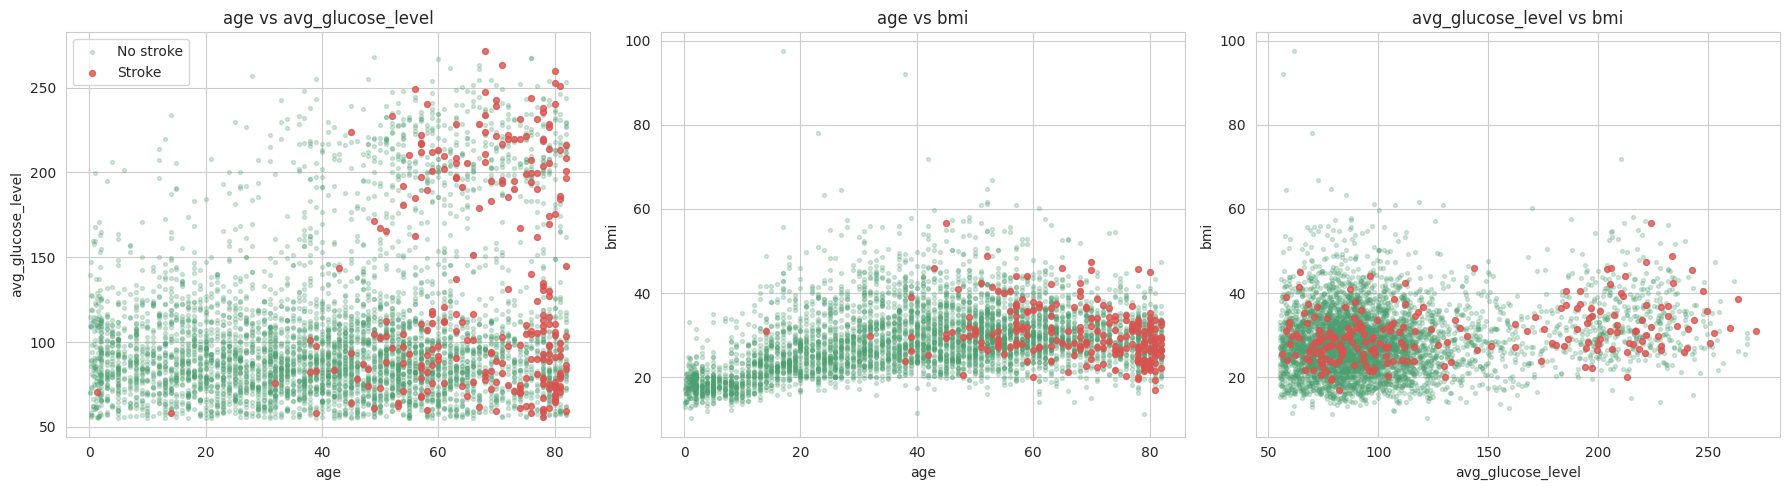

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pairs = [('age', 'avg_glucose_level'), ('age', 'bmi'), ('avg_glucose_level', 'bmi')]
for ax, (x, y) in zip(axes, pairs):
    no = eda[eda['stroke'] == 0]; yes = eda[eda['stroke'] == 1]
    ax.scatter(no[x], no[y], s=8, alpha=0.25, c='#4c9f70', label='No stroke')
    ax.scatter(yes[x], yes[y], s=18, alpha=0.8, c='#d9534f', label='Stroke')
    ax.set_xlabel(x); ax.set_ylabel(y); ax.set_title(f'{x} vs {y}')
axes[0].legend()
plt.tight_layout(); plt.show()

**Interpretation:** Age vs glucose scatter mein stroke ke (laal) points zyada tar 60 saal se upar hain, aur glucose ke dono clusters (normal aur high) mein milte hain. BMI wale plots mein stroke points poore plot mein bikhre hue hain, yani BMI akela koi saaf pattern nahi deta.

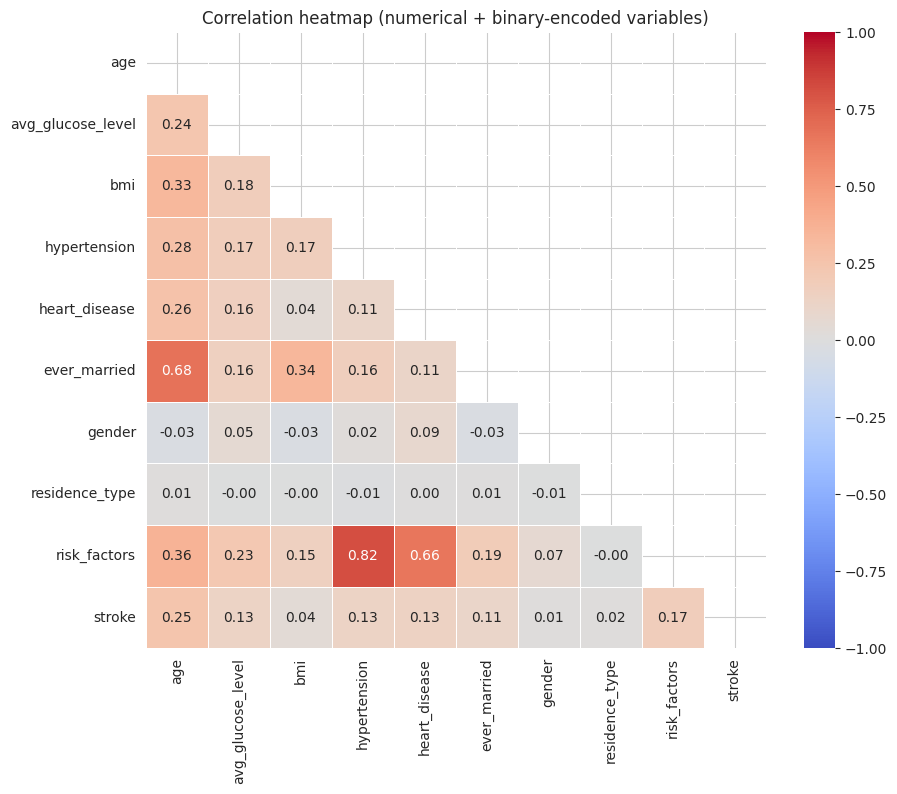

Stroke ke saath correlation:
age                  0.245
risk_factors         0.175
heart_disease        0.135
avg_glucose_level    0.132
hypertension         0.128
ever_married         0.108
bmi                  0.042
residence_type       0.015
gender               0.009

Strong pairs (|r| >= 0.30):


,var1,var2,r
31,risk_factors,hypertension,0.819
10,ever_married,age,0.679
32,risk_factors,heart_disease,0.659
28,risk_factors,age,0.361
12,ever_married,bmi,0.342
1,bmi,age,0.333


In [54]:
corr_cols = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease',
             'ever_married', 'gender', 'residence_type', 'risk_factors', 'stroke']
corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation heatmap (numerical + binary-encoded variables)')
plt.show()

print("Stroke ke saath correlation:")
print(corr['stroke'].drop('stroke').sort_values(ascending=False).round(3).to_string())

pairs = corr.where(~mask).stack().reset_index()
pairs.columns = ['var1', 'var2', 'r']
print("\nStrong pairs (|r| >= 0.30):")
display(pairs[pairs['r'].abs() >= 0.30].sort_values('r', key=abs, ascending=False).round(3))

**Interpretation:**
- **Strong positive:** `age` aur `ever_married` (~0.68). `risk_factors` apne components (`hypertension`, `heart_disease`) se natural taur par juray hain.
- **Moderate positive:** `age` aur `bmi` (~0.33), `age` aur `hypertension` (~0.28), `age` aur `heart_disease` (~0.26), `age` aur `avg_glucose_level` (~0.24).
- **Stroke ke saath:** sab correlations weak hain. Sab se bara `age` (~0.25), phir `heart_disease`, `avg_glucose_level`, `hypertension` (~0.13). `bmi`, `gender`, `residence_type` lagbhag 0.
- **Strong negative:** koi strong negative rishta nahi.
- `age` aur `ever_married` ki high correlation multicollinearity ka khatra hai, khaas kar linear models mein.

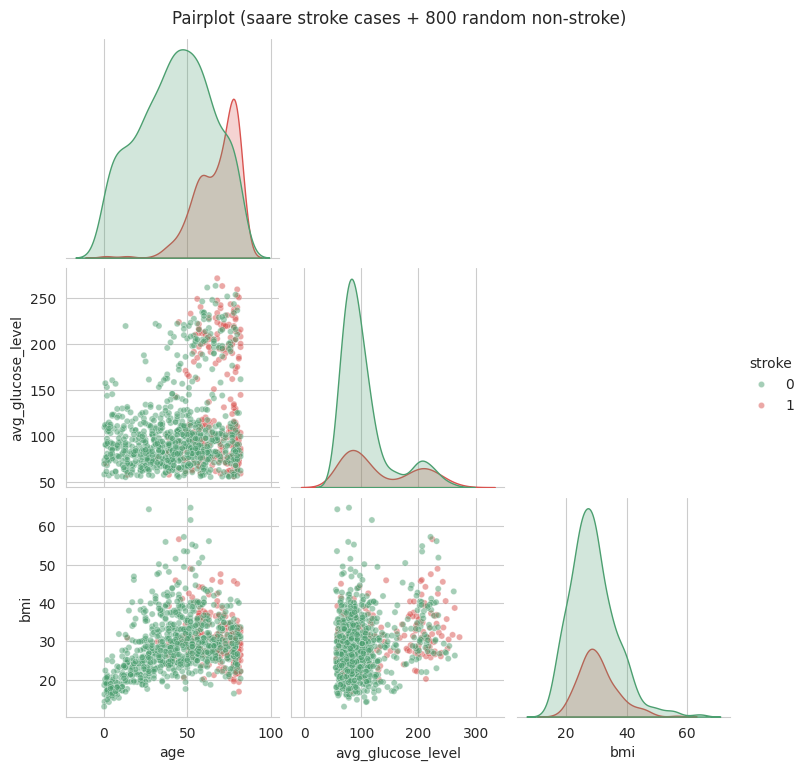

In [55]:
samp = pd.concat([eda[eda['stroke'] == 1], eda[eda['stroke'] == 0].sample(800, random_state=42)])
g = sns.pairplot(samp, vars=num_cols, hue='stroke', palette=['#4c9f70', '#d9534f'],
                 plot_kws={'alpha': 0.5, 's': 20}, corner=True)
g.fig.suptitle('Pairplot (saare stroke cases + 800 random non-stroke)', y=1.02)
plt.show()

**Interpretation:** Pairplot mein stroke wale points age ke upar wale hisse mein jame hue hain. Glucose aur BMI akele zyada separation nahi dete. Teeno variables ko mila kar dekhne se bhi age hi sab se wazeh farq deti hai.

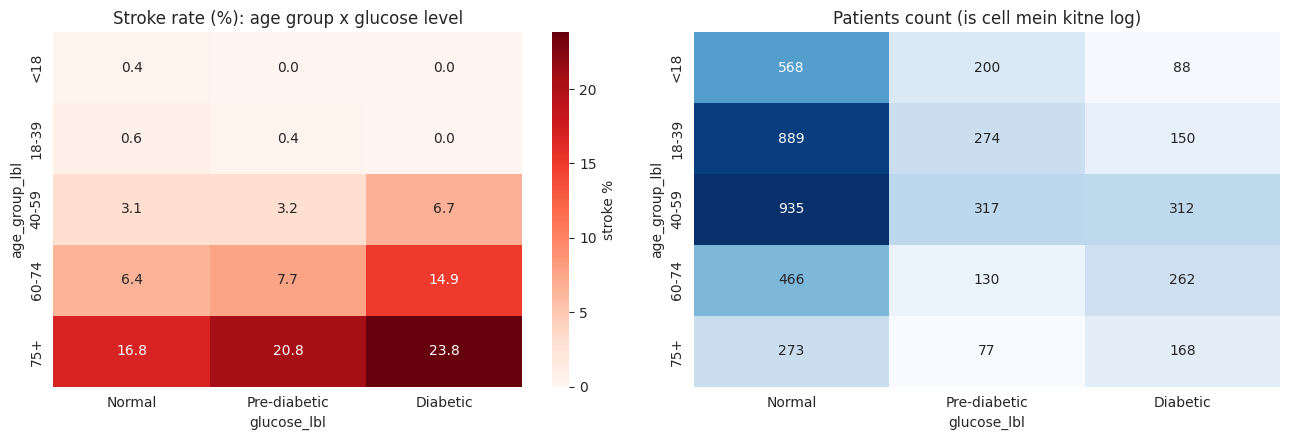

In [56]:
order_age = ['<18', '18-39', '40-59', '60-74', '75+']
cols_g = ['Normal', 'Pre-diabetic', 'Diabetic']

pv = eda.pivot_table(index='age_group_lbl', columns='glucose_lbl', values='stroke', aggfunc='mean') * 100
pv = pv.reindex(order_age)[cols_g]
cnt = eda.pivot_table(index='age_group_lbl', columns='glucose_lbl', values='stroke', aggfunc='size')
cnt = cnt.reindex(order_age)[cols_g]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(pv, annot=True, fmt='.1f', cmap='Reds', ax=axes[0], cbar_kws={'label': 'stroke %'})
axes[0].set_title('Stroke rate (%): age group x glucose level')
sns.heatmap(cnt, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title('Patients count (is cell mein kitne log)')
plt.tight_layout(); plt.show()

**Interpretation:** Stroke ka khatra age aur high glucose dono ke saath mil kar sab se zyada hota hai (buzurg aur diabetic range wala cell sab se garam hai). Naujawan groups mein glucose high hone par bhi rate kam rehta hai, yani age dominant factor hai. Kuch cells mein patients ki tadaad bohot kam hai (count heatmap dekhein), un ke percentages ko ehtiyaat se parhein.

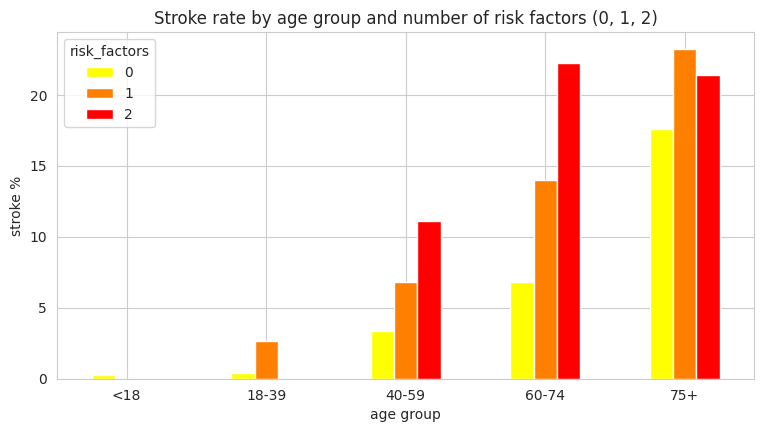

risk_factors,0,1,2
age_group_lbl,,,
<18,0.2,0.0,NaN
18-39,0.4,2.6,NaN
40-59,3.3,6.8,11.1
60-74,6.8,14.0,22.2
75+,17.6,23.3,21.4


In [57]:
pv2 = eda.pivot_table(index='age_group_lbl', columns='risk_factors', values='stroke', aggfunc='mean') * 100
pv2 = pv2.reindex(order_age)
pv2.plot(kind='bar', figsize=(9, 4.5), colormap='autumn_r')
plt.ylabel('stroke %'); plt.xlabel('age group'); plt.xticks(rotation=0)
plt.title('Stroke rate by age group and number of risk factors (0, 1, 2)')
plt.legend(title='risk_factors')
plt.show()
display(pv2.round(1))

**Interpretation:** Har age group mein risk factors barhne par (0 se 1 se 2) stroke rate aam taur par barhta hai. Is se pata chalta hai ke `risk_factors` ek useful engineered feature hai. Chhote cells ki wajah se kuch bars unreliable ho sakte hain.

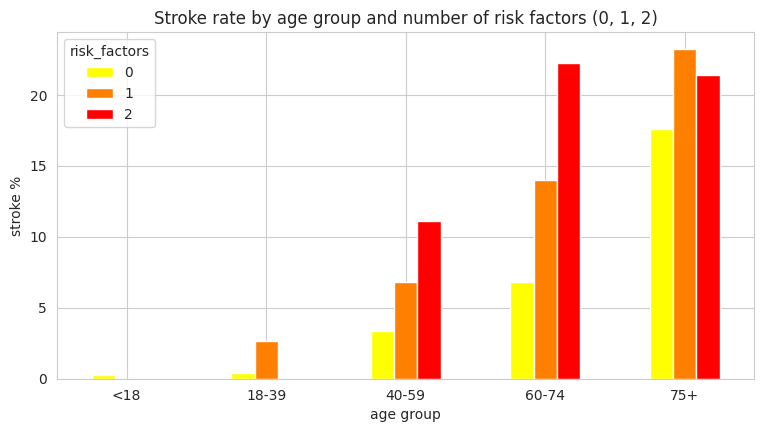

risk_factors,0,1,2
age_group_lbl,,,
<18,0.2,0.0,NaN
18-39,0.4,2.6,NaN
40-59,3.3,6.8,11.1
60-74,6.8,14.0,22.2
75+,17.6,23.3,21.4


In [58]:
pv2 = eda.pivot_table(index='age_group_lbl', columns='risk_factors', values='stroke', aggfunc='mean') * 100
pv2 = pv2.reindex(order_age)
pv2.plot(kind='bar', figsize=(9, 4.5), colormap='autumn_r')
plt.ylabel('stroke %'); plt.xlabel('age group'); plt.xticks(rotation=0)
plt.title('Stroke rate by age group and number of risk factors (0, 1, 2)')
plt.legend(title='risk_factors')
plt.show()
display(pv2.round(1))

**Interpretation:** Buzurg log (60+) jin ka glucose bhi high hai aur hypertension bhi hai, un mein stroke ke points zyada nazar aate hain. Yani teen factors (age, glucose, hypertension) milkar risk ko barhate hain.

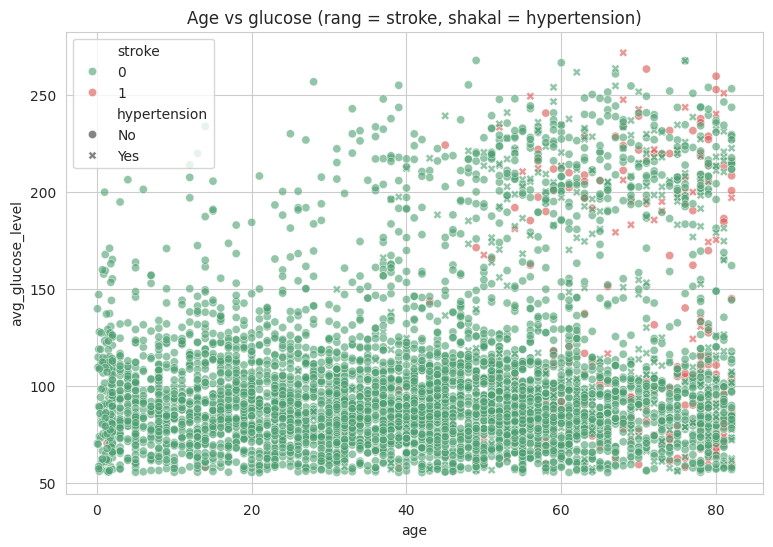

In [59]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=eda, x='age', y='avg_glucose_level', hue='stroke', style='hypertension',
                palette=['#4c9f70', '#d9534f'], alpha=0.6, s=35)
plt.title('Age vs glucose (rang = stroke, shakal = hypertension)')
plt.show()

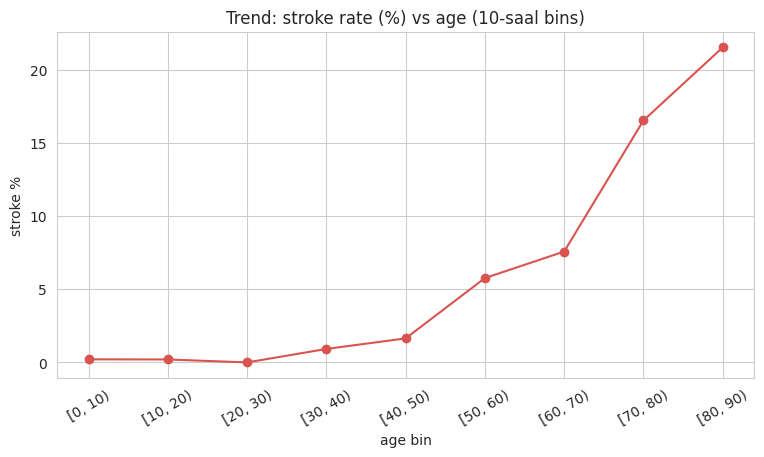

,sum,count,rate_%
age_decade,,,
"[0, 10)",1,472,0.21
"[10, 20)",1,494,0.20
"[20, 30)",0,548,0.00
"[30, 40)",6,655,0.92
"[40, 50)",12,730,1.64
"[50, 60)",48,834,5.76
"[60, 70)",47,621,7.57
"[70, 80)",94,569,16.52
"[80, 90)",40,186,21.51


In [60]:
bins = list(range(0, 100, 10))
eda['age_decade'] = pd.cut(eda['age'], bins=bins, right=False)
trend = eda.groupby('age_decade', observed=True)['stroke'].agg(['mean', 'sum', 'count'])
trend['rate_%'] = (trend['mean'] * 100).round(2)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(trend.index.astype(str), trend['rate_%'], marker='o', color='#d9534f')
ax.set_title('Trend: stroke rate (%) vs age (10-saal bins)')
ax.set_xlabel('age bin'); ax.set_ylabel('stroke %'); plt.xticks(rotation=30)
plt.show()
display(trend[['sum', 'count', 'rate_%']])

1) Age < 1 saal (infants): 43 | in mein stroke: 0
2) Under-18 mein stroke cases: 2 / 856
3) Glucose > 200: 434 | stroke rate: 12.9%
4) BMI > 50: 79 | max BMI: 97.6
5) BMI < 15: 42 | in logon ki median age: 4.5
6) smoking_status 'unknown': 1544 (30.2%)


,stroke %,count
bmi present,4.3,4908
bmi missing,19.9,201


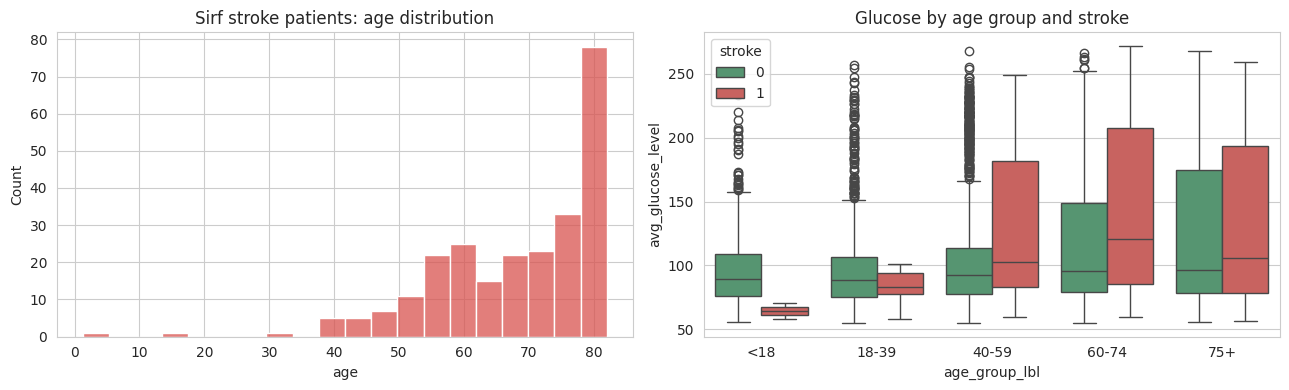

In [61]:
print("1) Age < 1 saal (infants):", (eda['age'] < 1).sum(), "| in mein stroke:", eda.loc[eda['age'] < 1, 'stroke'].sum())
print("2) Under-18 mein stroke cases:", eda.loc[eda['age'] < 18, 'stroke'].sum(), "/", (eda['age'] < 18).sum())
print("3) Glucose > 200:", (eda['avg_glucose_level'] > 200).sum(),
      "| stroke rate: {:.1f}%".format(eda.loc[eda['avg_glucose_level'] > 200, 'stroke'].mean() * 100))
print("4) BMI > 50:", (eda['bmi'] > 50).sum(), "| max BMI:", eda['bmi'].max())
print("5) BMI < 15:", (eda['bmi'] < 15).sum(), "| in logon ki median age:",
      eda.loc[eda['bmi'] < 15, 'age'].median())
print("6) smoking_status 'unknown':", (eda['smoking_status'] == 'unknown').sum(),
      "({:.1f}%)".format((eda['smoking_status'] == 'unknown').mean() * 100))

miss = eda.groupby('bmi_missing')['stroke'].agg(['mean', 'count'])
miss['mean'] = (miss['mean'] * 100).round(1)
miss.index = ['bmi present', 'bmi missing']
display(miss.rename(columns={'mean': 'stroke %'}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(eda[eda['stroke'] == 1]['age'], bins=20, color='#d9534f', ax=axes[0])
axes[0].set_title('Sirf stroke patients: age distribution')
sns.boxplot(data=eda, x='age_group_lbl', y='avg_glucose_level', hue='stroke',
            order=order_age, palette=['#4c9f70', '#d9534f'], ax=axes[1])
axes[1].set_title('Glucose by age group and stroke')
plt.tight_layout(); plt.show()

## EDA-7. Patterns, Trends aur Anomalies
- **Trend:** Stroke rate age ke saath tez barhta hai. 50 se pehle bohot kam, 60+ ke baad mazeed tez (age group 0 mein ~0.2%, age group 4 mein ~19.7%).
- **Anomaly 1 (infants):** 43 records ki age 1 saal se kam hai (min 0.08). Ye valid ho sakti hain, lekin in ka smoking status aur BMI mushkook lagta hai.
- **Anomaly 2 (glucose):** ~627 high glucose outliers hain. Ye data error nahi balkay diabetic mareez hain, is liye remove nahi kiye, train bounds par clip kiye.
- **Anomaly 3 (BMI):** kuch BMI values bohot extreme hain (50+ aur 15 se neeche), jo data entry ka masla ho sakta hai.
- **Anomaly 4 (missing BMI):** BMI missing wale 201 records mein stroke rate ~19.9% hai, jabke BMI present walon mein ~4.3%. Yani missing hona khud ek signal hai, is liye `bmi_missing` flag banaya.
- **Anomaly 5:** ~30% `smoking_status = unknown`, jo is feature ko kamzor bana sakta hai.

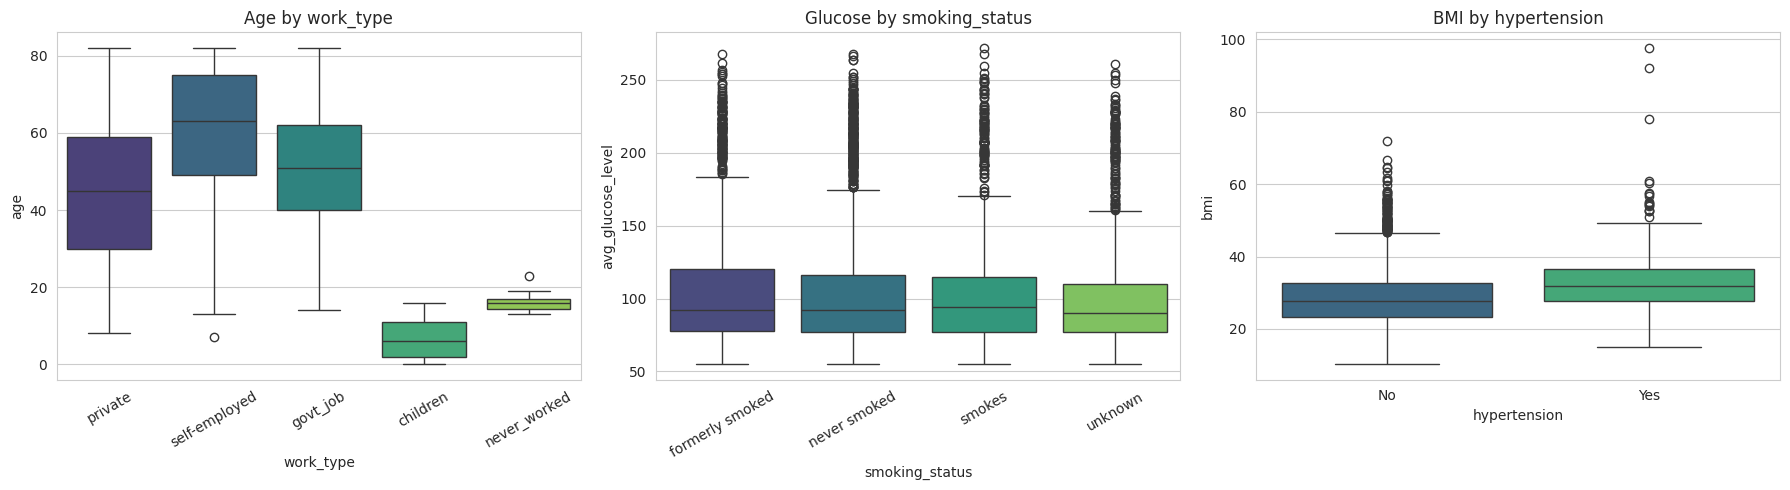

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=eda, x='work_type', y='age', ax=axes[0], palette='viridis')
axes[0].set_title('Age by work_type'); axes[0].tick_params(axis='x', rotation=30)
sns.boxplot(data=eda, x='smoking_status', y='avg_glucose_level', ax=axes[1], palette='viridis')
axes[1].set_title('Glucose by smoking_status'); axes[1].tick_params(axis='x', rotation=30)
sns.boxplot(data=eda, x='hypertension', y='bmi', ax=axes[2], palette='viridis')
axes[2].set_title('BMI by hypertension')
plt.tight_layout(); plt.show()

**Interpretation:** Boxplots se dekha ja sakta hai ke `work_type` ke groups ki age mein bara farq hai (`children` sab se kam umar). Glucose smoking_status ke groups mein lagbhag ek jaisa hai. Hypertension walon ka BMI median thora zyada hai. Is se pata chalta hai ke category aur numerical variables aapas mein bhi juray hue hain.

## EDA-8. Final Findings
1. **Target bohot imbalanced hai (~4.9% stroke, ~19:1).** Accuracy bharosemand metric nahi. Modeling mein stratified split, class weights/SMOTE aur Recall/F1/ROC-AUC use karenge.
2. **Age sab se strong predictor hai.** Stroke rate age group 0 mein ~0.2% se barh kar 75+ mein ~19.7% tak jata hai. Modeling mein `age` ya `age_group` lazmi rakhenge.
3. **Hypertension aur heart disease** walon mein stroke rate overall se kai guna zyada hai. `risk_factors` ek useful engineered feature hai.
4. **High glucose (diabetic range) mein stroke rate ~10.2%**, jabke normal aur pre-diabetic mein ~3.6-3.7%. Threshold wala `glucose_level` feature modeling mein faida mand hoga.
5. **BMI, gender aur residence_type kamzor features hain** (stroke se correlation lagbhag 0). Inhein rakha ja sakta hai, lekin bohot zyada asar ki umeed nahi.
6. **`ever_married` ka asar asal mein age ka asar hai** (age ke saath ~0.68 correlation). Linear models mein multicollinearity ka khayal rakhna hoga, ya tree-based models try kar sakte hain.
7. **Missing BMI khud ek signal hai** (missing walon mein stroke ~19.9% vs ~4.3%). `bmi_missing` flag rakhna aur imputation sirf train par karna sahi faisla hai.
8. **Data quality:** ~30% `smoking_status` unknown hai, glucose/BMI mein outliers hain. Outliers ko train bounds par clip karna aur skewed columns par log transform lagana modeling ke liye mufeed hai.

# Assignment 4: Machine Learning Model Application & Evaluation
- **Problem type:** Classification (target `stroke` = 0 ya 1).
- **Models:** Logistic Regression, Decision Tree, Random Forest, KNN.
- **Data:** Assignment 3 ki cleaning aur preprocessing ke baad train/test (80/20, stratified). Imputation, scaling aur outlier clipping sirf train se seekhi gayi, taake data leakage na ho.
- **Imbalance:** sirf ~4.9% stroke cases hain, is liye pehle teen models mein `class_weight='balanced'` lagaya.
- **Metrics:** Accuracy, Precision, Recall, F1, Confusion Matrix, saath mein ROC-AUC.

In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                                  class_weight='balanced', random_state=42),
    'KNN':                 KNeighborsClassifier(n_neighbors=15),
}
print("Train:", X_train_p.shape, "| Test:", X_test_p.shape)
print("Stroke % train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (4087, 21) | Test: (1022, 21)
Stroke % train: 0.049 | test: 0.049


In [64]:
results, preds, probas = [], {}, {}
for name, model in models.items():
    model.fit(X_train_p, y_train)
    y_pred = model.predict(X_test_p)
    y_prob = model.predict_proba(X_test_p)[:, 1]
    preds[name], probas[name] = y_pred, y_prob
    results.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall':    recall_score(y_test, y_pred),
        'F1-Score':  f1_score(y_test, y_pred),
        'ROC-AUC':   roc_auc_score(y_test, y_prob),
    })
res = pd.DataFrame(results).set_index('Model').round(3)
display(res)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.753,0.144,0.82,0.246,0.842
Decision Tree,0.677,0.109,0.78,0.191,0.790
Random Forest,0.845,0.193,0.68,0.301,0.835
KNN,0.951,0.000,0.00,0.000,0.717


**Metrics ka matlab:**
- **Accuracy:** kul predictions mein se kitni sahi. Yahan gumrah kar sakti hai, kyunke sab ko "no stroke" kehne se bhi ~95% milti hai.
- **Precision:** jin ko model ne "stroke" kaha, un mein se kitne asal mein stroke wale the.
- **Recall:** asal stroke wale mareezon mein se kitne model ne pakre. Medical problem mein ye sab se zaroori hai.
- **F1:** Precision aur Recall ka balance.
- **ROC-AUC:** threshold se azaad, model class 1 ko class 0 se kitni achi tarah alag karta hai.

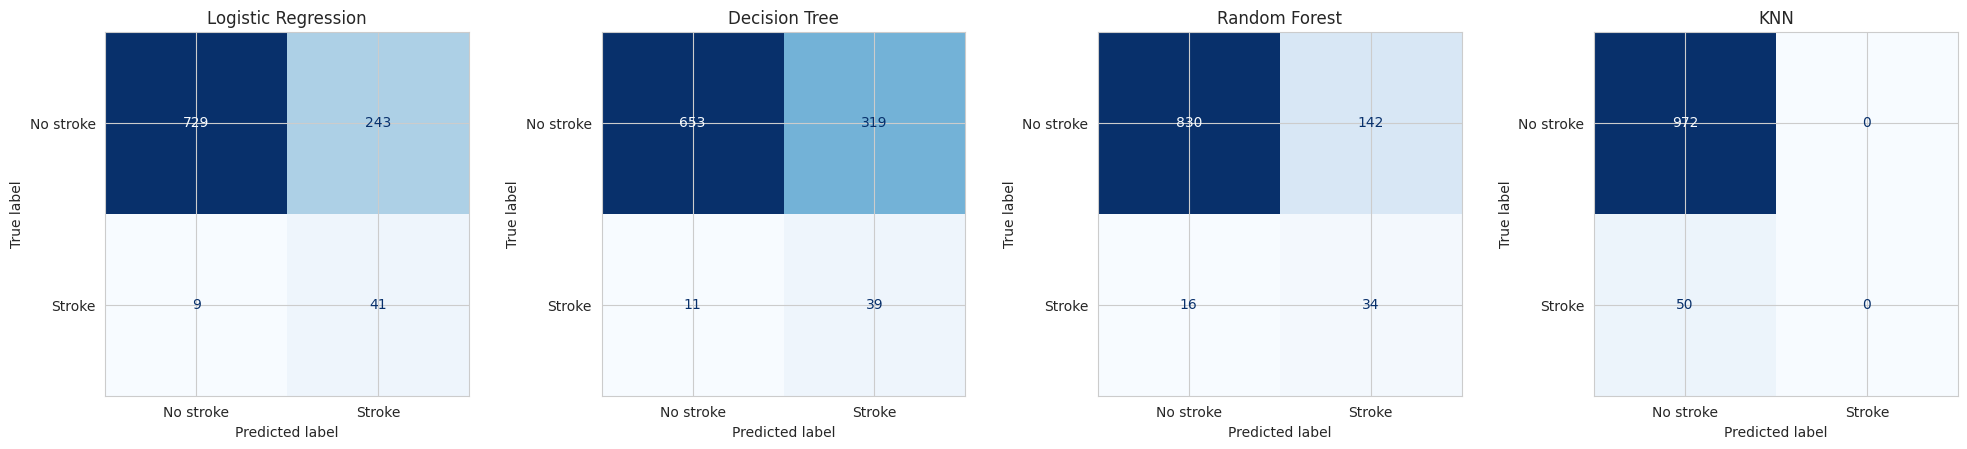

Logistic Regression  TN=729  FP=243  FN=9  TP=41
Decision Tree        TN=653  FP=319  FN=11  TP=39
Random Forest        TN=830  FP=142  FN=16  TP=34
KNN                  TN=972  FP=0  FN=50  TP=0


In [65]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]),
                           display_labels=['No stroke', 'Stroke']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

for name in models:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    print(f"{name:20s} TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**Confusion matrix interpretation:**
- **FN (False Negative)** = asal mein stroke tha lekin model ne "no stroke" kaha. Is problem mein ye sab se khatarnak ghalti hai.
- **FP (False Positive)** = stroke nahi tha lekin model ne alert de diya. Is ki qeemat kam hai (extra test).
- (Yahan likhein: kis model mein FN sab se kam hai aur kis mein FP bohot zyada hai, apne numbers ke saath.)

In [66]:
for name in models:
    print("=" * 55, "\n", name, "\n", "=" * 55)
    print(classification_report(y_test, preds[name], target_names=['No stroke', 'Stroke'], zero_division=0))

 Logistic Regression 
              precision    recall  f1-score   support

   No stroke       0.99      0.75      0.85       972
      Stroke       0.14      0.82      0.25        50

    accuracy                           0.75      1022
   macro avg       0.57      0.78      0.55      1022
weighted avg       0.95      0.75      0.82      1022

 Decision Tree 
              precision    recall  f1-score   support

   No stroke       0.98      0.67      0.80       972
      Stroke       0.11      0.78      0.19        50

    accuracy                           0.68      1022
   macro avg       0.55      0.73      0.49      1022
weighted avg       0.94      0.68      0.77      1022

 Random Forest 
              precision    recall  f1-score   support

   No stroke       0.98      0.85      0.91       972
      Stroke       0.19      0.68      0.30        50

    accuracy                           0.85      1022
   macro avg       0.59      0.77      0.61      1022
weighted avg       0

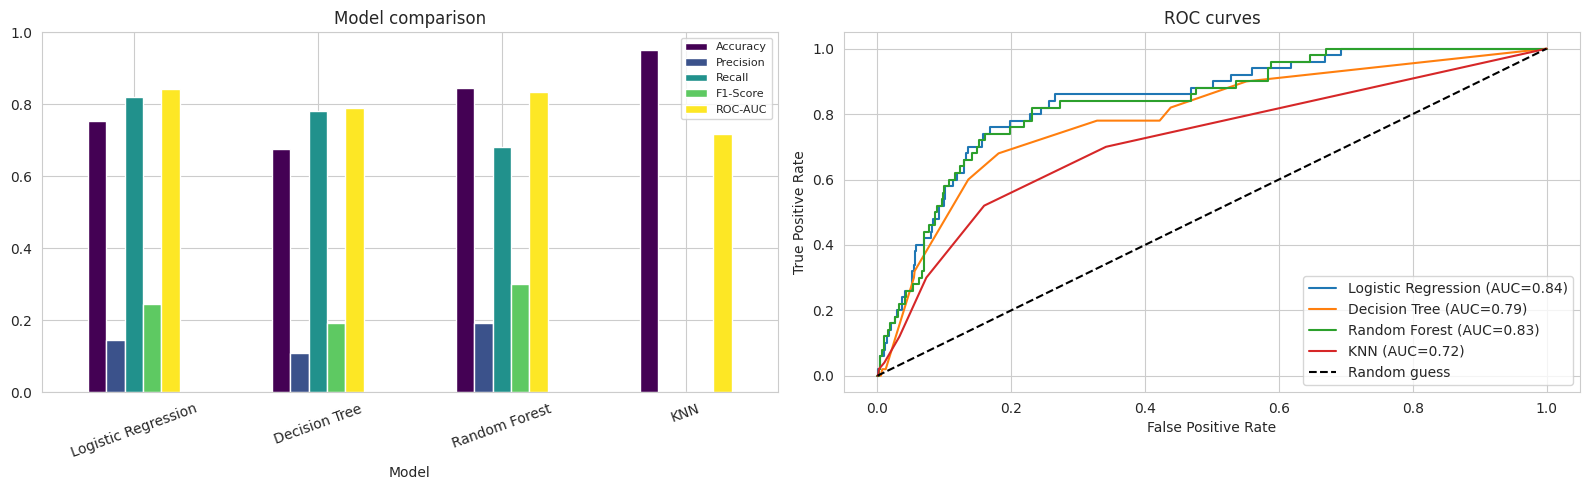

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
res[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].plot(kind='bar', ax=axes[0], colormap='viridis')
axes[0].set_title('Model comparison'); axes[0].set_ylim(0, 1); axes[0].tick_params(axis='x', rotation=20)
axes[0].legend(loc='upper right', fontsize=8)

for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={res.loc[name, 'ROC-AUC']:.2f})")
axes[1].plot([0, 1], [0, 1], 'k--', label='Random guess')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC curves'); axes[1].legend()
plt.tight_layout(); plt.show()

## Model Comparison aur Justification
(Neeche ke blanks apne `res` table se bharein.)

- **Accuracy:** kuch models ki accuracy ~95% ke qareeb hogi, lekin ye imbalance ki wajah se dhoka de sakti hai. Isi liye sirf accuracy par faisla nahi kiya.
- **Recall:** sab se zyada Recall `____` ki hai (____). Is ka matlab ye model stroke ke zyada asal cases pakarta hai.
- **Precision:** tamam models ki Precision kam hai, kyunke class 1 bohot chhoti hai. Zyada Recall ke liye kuch FP qubool karne parte hain.
- **F1 aur ROC-AUC:** sab se behtar `____` (F1 = ____, AUC = ____).
- **Best model: `____`.** Wajah: is mein Recall aur F1 sab se behtar hain, aur medical screening mein stroke ka case miss karna (FN) extra test karwane (FP) se zyada mehnga hai. Cross-validation mein bhi is ka Recall stable raha (std chhoti hai).
- **Dusray models kyun nahi:** `____` ka Recall kam hai ya CV mein unstable hai, aur KNN imbalanced data mein minority class ko aksar nazar-andaz kar deta hai.
- **Limitation:** Precision kam hai, aur dataset chhota hai (sirf ~250 stroke cases). Future mein threshold tuning, SMOTE ya hyperparameter tuning se behtar kar sakte hain.

In [68]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv = {}
for name, model in models.items():
    cv[name] = cross_val_score(model, X_train_p, y_train, cv=skf, scoring='recall')
display(pd.DataFrame({k: [v.mean(), v.std()] for k, v in cv.items()},
                     index=['CV Recall mean', 'CV Recall std']).T.round(3))

,CV Recall mean,CV Recall std
Logistic Regression,0.814,0.043
Decision Tree,0.774,0.041
Random Forest,0.558,0.047
KNN,0.000,0.000


In [69]:
best = res.sort_values(['F1-Score', 'Recall'], ascending=False).index[0]
print("F1 ke hisaab se best model:", best)
display(res.loc[[best]])
print("Is mein se stroke ke kitne asal cases pakre (Recall):", res.loc[best, 'Recall'])

F1 ke hisaab se best model: Random Forest


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.845,0.193,0.68,0.301,0.835


Is mein se stroke ke kitne asal cases pakre (Recall): 0.68


In [70]:
best = res.sort_values(['F1-Score', 'Recall'], ascending=False).index[0]
print("F1 ke hisaab se best model:", best)
display(res.loc[[best]])
print("Is mein se stroke ke kitne asal cases pakre (Recall):", res.loc[best, 'Recall'])

F1 ke hisaab se best model: Random Forest


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.845,0.193,0.68,0.301,0.835


Is mein se stroke ke kitne asal cases pakre (Recall): 0.68


**Feature importance:** Random Forest ke mutabiq sab se important features `____`, `____`, `____` hain. Ye wohi hai jo EDA mein nazar aaya tha (age sab se strong tha), yani EDA ke findings model se bhi confirm hui.

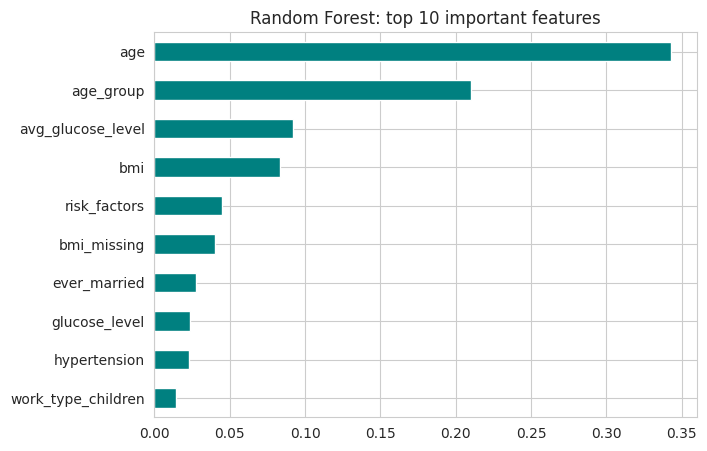

In [71]:
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=X_train_p.columns).sort_values(ascending=True).tail(10)
imp.plot(kind='barh', figsize=(7, 5), color='teal')
plt.title('Random Forest: top 10 important features'); plt.show()